# Further Solar Parks

The model trained on Talatan (2020) is applied unchanged to four large solar parks in very different settings. There are no hand labels for them, so the notebook reports the predicted PV area and shows the result on maps for a visual check. Same steps and settings as in notebook 04.

| Park | Country | Setting |
| --- | --- | --- |
| Khavda | India | salt desert of the Rann of Kutch near sea level, bifacial modules and wind turbines, still growing fast |
| Energiepark Witznitz | Germany | reclaimed lignite mine south of Leipzig, among fields, forest, villages and mine lakes |
| Francisco Pizarro | Spain | Mediterranean dehesa, single-axis trackers with wide row spacing |
| Núñez de Balboa | Spain | bright, dry farmland on chalky soils, long curved rows of modules |

The reference areas are those given by the operators. Except for Witznitz they refer to the whole plant site, including the space between the rows, so the module area is smaller.

## Setup

In [3]:
import sys
from pathlib import Path

import geoai
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

sys.path.append("../scripts")
from preprocessing import BASELINE_OFFSET, scale_to_byte
from scene_search import download_scene, search_scenes

BASE_DIR = Path().resolve().parent if Path().resolve().name == "notebooks" else Path().resolve()
DATA_DIR = BASE_DIR / "data"
SCENE_DIR = DATA_DIR / "raw" / "raster" / "sentinel2"
SCALED_DIR = DATA_DIR / "processed" / "scaled"
MODEL_DIR = BASE_DIR / "models"
PREDICTIONS_DIR = BASE_DIR / "results" / "predictions"
EVALUATION_DIR = BASE_DIR / "results" / "evaluation"
FIGURES_DIR = BASE_DIR / "results" / "figures"

MODEL_FILE = "talatan_unet.pth"
NUM_CHANNELS = 6
MIN_AREA_M2 = 10_000   # smallest polygon kept in the vector output (1 ha), as in notebook 04

# Study area [min_lon, min_lat, max_lon, max_lat] in WGS84, UTM zone, scene day,
# and the area given by the operator in km² (None if unknown)
SITES = {
    "khavda": {
        "name": "Khavda", "bbox": [69.25, 23.95, 69.65, 24.22], "crs": "EPSG:32642",
        "day": "2026-10-04", "reference_km2": None,
    },
    "witznitz": {
        "name": "Energiepark Witznitz", "bbox": [12.37, 51.14, 12.47, 51.20], "crs": "EPSG:32633",
        "day": "2026-08-15", "reference_km2": 3.0,    # 300 ha covered by modules
    },
    "pizarro": {
        "name": "Francisco Pizarro", "bbox": [-5.750, 39.505, -5.625, 39.612], "crs": "EPSG:32630",
        "day": "2026-10-14", "reference_km2": 13.0,   # 1,300 ha plant site
    },
    "balboa": {
        "name": "Núñez de Balboa", "bbox": [-6.272, 38.417, -6.180, 38.489], "crs": "EPSG:32629",
        "day": "2026-10-27", "reference_km2": 10.0,   # about 1,000 ha plant site
    },
}

for folder in (SCENE_DIR, SCALED_DIR, PREDICTIONS_DIR, EVALUATION_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

## Download and Prediction

For every park: load the scene of the chosen day on its own UTM grid, prepare it as in notebook 04 (baseline offset, scaling per band), predict, and convert the mask to polygons. Scenes that are already on disk are not downloaded again.

In [4]:
rows = []

for site, info in SITES.items():
    day = info["day"]
    found = search_scenes(info["bbox"], day, day, max_cloud=100)
    if not found:
        raise ValueError(f"{site}: no scene on {day} covers the study area")

    raw_scene = download_scene(found[0]["items"], info["bbox"], SCENE_DIR / f"{site}_{day}.tif", crs=info["crs"])
    scene = scale_to_byte(raw_scene, SCALED_DIR / f"{site}_{day}_scaled.tif", offset=BASELINE_OFFSET)

    mask_path = PREDICTIONS_DIR / f"prediction_{site}_{day}.tif"
    probability_path = PREDICTIONS_DIR / f"probability_{site}_{day}.tif"
    geoai.semantic_segmentation(
        input_path=str(scene),
        output_path=str(mask_path),
        model_path=str(MODEL_DIR / MODEL_FILE),
        probability_path=str(probability_path),
        architecture="unet",
        encoder_name="resnet34",
        num_channels=NUM_CHANNELS,
        num_classes=2,
        window_size=384,
        overlap=192,
        batch_size=4,
    )

    polygons = geoai.raster_to_vector(
        str(mask_path),
        output_path=str(PREDICTIONS_DIR / f"prediction_{site}_{day}.gpkg"),
        threshold=0,
        min_area=MIN_AREA_M2,
        output_format="gpkg",
    )

    with rasterio.open(mask_path) as src:
        predicted = src.read(1) == 1
        pixel_area = abs(src.transform.a * src.transform.e)

    info.update(scene=scene, mask_path=mask_path, probability_path=probability_path)
    rows.append({
        "site": site,
        "date": day,
        "predicted_km2": round(predicted.sum() * pixel_area / 1e6, 2),
        "area_in_polygons_over_1ha_km2": round(polygons.area.sum() / 1e6, 2),
        "operator_km2": info["reference_km2"],
    })
    print(f"{info['name']:22s} {day}: {rows[-1]['predicted_km2']:7.2f} km²")

areas = pd.DataFrame(rows).set_index("site")
areas.to_csv(EVALUATION_DIR / "area_transfer_sites.csv")
areas

  0%|          | 0/315 [00:00<?, ?it/s]

Khavda                 2026-10-04:  223.58 km²


  0%|          | 0/9 [00:00<?, ?it/s]

Energiepark Witznitz   2026-08-15:    4.10 km²


  0%|          | 0/30 [00:00<?, ?it/s]

Francisco Pizarro      2026-10-14:   21.08 km²


  0%|          | 0/16 [00:00<?, ?it/s]

Núñez de Balboa        2026-10-27:    8.58 km²


,date,predicted_km2,area_in_polygons_over_1ha_km2,operator_km2
site,,,,
khavda,2026-10-04,223.58,223.31,NaN
witznitz,2026-08-15,4.10,4.05,3.0
pizarro,2026-10-14,21.08,21.01,13.0
balboa,2026-10-27,8.58,8.53,10.0


## Maps

For every park: the scene, the predicted PV area in red, and the probability of the PV class. Without labels, these maps are the only check. Look for missed module fields and for false positives on dark water, bare soil, scrub, villages and roads.

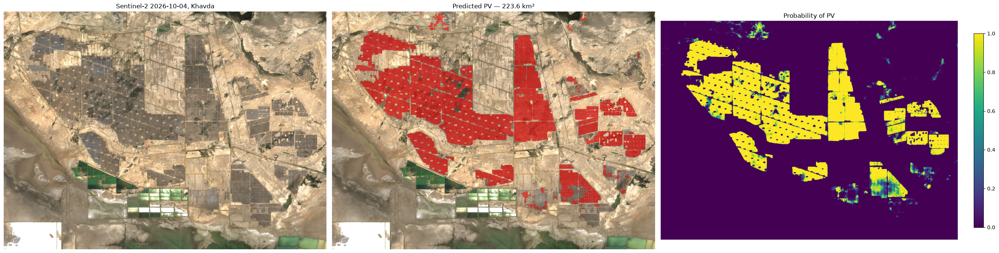

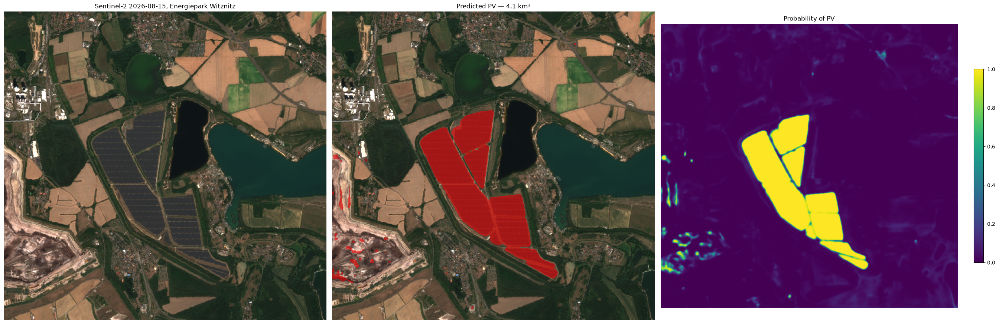

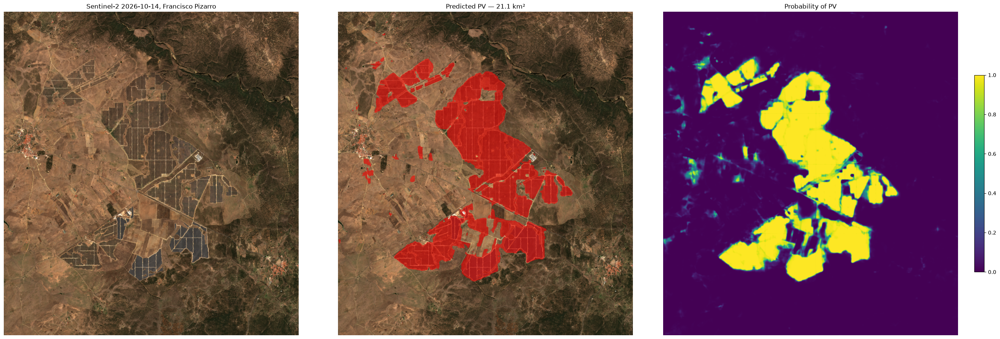

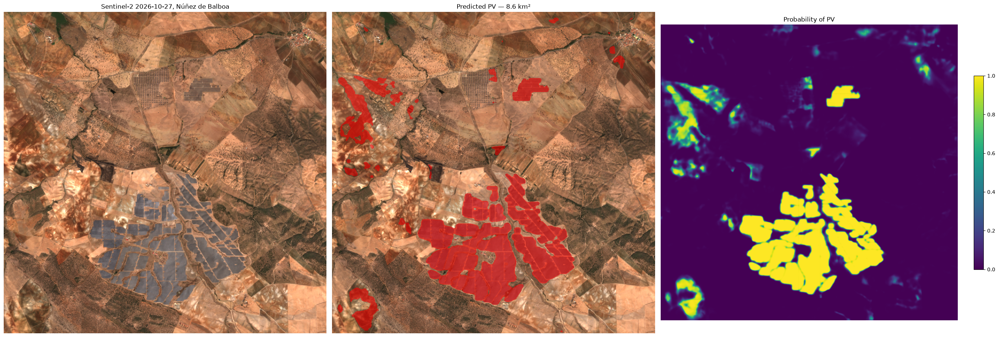

In [5]:
for site, info in SITES.items():
    with rasterio.open(info["scene"]) as src:
        F = max(1, max(src.height, src.width) // 1500)   # keep the display size manageable
        small_shape = (src.height // F, src.width // F)
        rgb = src.read([3, 2, 1], out_shape=(3, *small_shape))
    rgb = np.clip(np.moveaxis(rgb, 0, -1) / 191, 0, 1)   # 191 = reflectance 3000 after scaling

    with rasterio.open(info["mask_path"]) as src:
        mask = src.read(1, out_shape=small_shape) == 1
    with rasterio.open(info["probability_path"]) as src:
        probability = src.read(2, out_shape=small_shape)

    overlay = rgb.copy()
    overlay[mask] = 0.45 * overlay[mask] + 0.55 * np.array([1.0, 0.0, 0.0])

    fig, axes = plt.subplots(1, 3, figsize=(27, 9))
    axes[0].imshow(rgb)
    axes[0].set_title(f"Sentinel-2 {info['day']}, {info['name']}")
    axes[1].imshow(overlay)
    axes[1].set_title(f"Predicted PV — {areas.loc[site, 'predicted_km2']:.1f} km²")
    im = axes[2].imshow(probability, cmap="viridis", vmin=0, vmax=1)
    axes[2].set_title("Probability of PV")
    fig.colorbar(im, ax=axes[2], fraction=0.03)
    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"prediction_{site}_{info['day']}.png", dpi=150, bbox_inches="tight")
    plt.show()